Google Drive je već povezan.
Koristi se uređaj: cuda


Računanje metrika: 100%|██████████| 3/3 [00:01<00:00,  1.97it/s]


--- Metrike Performansi Modela ---
  Tačnost (Accuracy): 97.90%
  Preciznost (Precision): 0.9676
  Odziv (Recall): 0.9841
  F1-skor (F1 Score): 0.9758
  IoU (Jaccard): 0.9527
------------------------------------



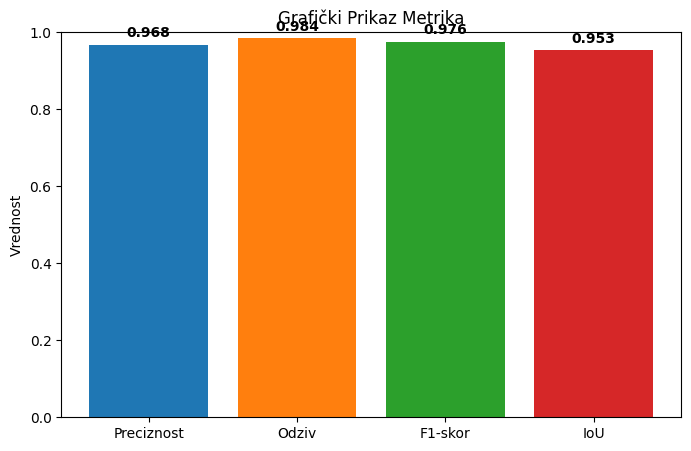

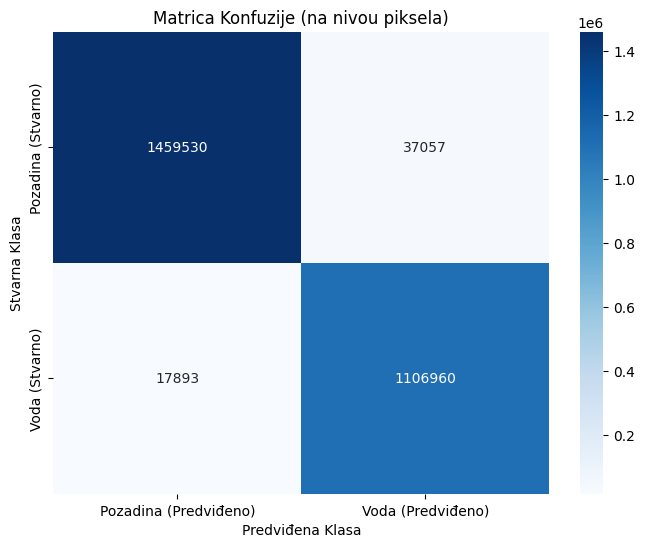

Čuvanje predikcija: 100%|██████████| 3/3 [00:03<00:00,  1.13s/it]

Predikcije sačuvane u folder: /content/predictions_from_saved_model/

Evaluacija i predikcije su uspešno završene.


In [10]:
# --- INSTALACIJA DODATNE BIBLIOTEKE ZA LEPŠE GRAFIKE ---
!pip install -q seaborn

# --- 1. Uvoz potrebnih biblioteka i osnovna podešavanja ---
import torch
import os
import cv2
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import torch.nn as nn
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# --- 2. Povezivanje sa Google Drive-om ---
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
else:
    print("Google Drive je već povezan.")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Koristi se uređaj: {DEVICE}")


# --- 3. Definicije klasa i funkcija ---

class WaterBodiesDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform
        all_files = os.listdir(image_dir)
        self.images = [name for name in all_files if name.lower().endswith('.png')]
    def __len__(self):
        return len(self.images)
    def __getitem__(self, index):
        img_name = self.images[index]
        img_path = os.path.join(self.image_dir, img_name)
        base_name, _ = os.path.splitext(img_name)
        mask_name = f"{base_name}_mask.png"
        mask_path = os.path.join(self.mask_dir, mask_name)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, 0)
        if mask is not None:
            mask[mask > 0] = 1.0
        else:
            print(f"Upozorenje: Maska '{mask_name}' nije pronađena za '{img_name}'. Koristi se prazna maska.")
            mask = np.zeros(image.shape[:2], dtype=np.float32)
        if self.transform is not None:
            augmentations = self.transform(image=image, mask=mask)
            image = augmentations["image"]
            mask = augmentations["mask"]
            mask = mask.long()
        return image, mask

def get_model(num_classes):
    model = models.segmentation.deeplabv3_resnet50(weights=None, aux_loss=False)
    model.classifier[4] = nn.Conv2d(256, num_classes, kernel_size=(1, 1), stride=(1, 1))
    return model

# >>>>>>>>> UNAPREĐENA FUNKCIJA SA GRAFICIMA <<<<<<<<<<
def evaluate_model(loader, model, device="cuda"):
    model.eval()
    total_tp, total_fp, total_fn, total_tn = 0, 0, 0, 0
    with torch.no_grad():
        for x, y in tqdm(loader, desc="Računanje metrika"):
            x, y = x.to(device), y.to(device).long()
            preds = torch.argmax(model(x)['out'], dim=1)
            preds_flat, y_flat = preds.flatten(), y.flatten()
            total_tp += ((preds_flat == 1) & (y_flat == 1)).sum().item()
            total_fp += ((preds_flat == 1) & (y_flat == 0)).sum().item()
            total_fn += ((preds_flat == 0) & (y_flat == 1)).sum().item()
            total_tn += ((preds_flat == 0) & (y_flat == 0)).sum().item()

    epsilon = 1e-8
    pixel_accuracy = (total_tp + total_tn) / (total_tp + total_tn + total_fp + total_fn + epsilon)
    precision = total_tp / (total_tp + total_fp + epsilon)
    recall = total_tp / (total_tp + total_fn + epsilon)
    f1_score = 2 * (precision * recall) / (precision + recall + epsilon)
    iou = total_tp / (total_tp + total_fp + total_fn + epsilon)

    print("\n--- Metrike Performansi Modela ---")
    print(f"  Tačnost (Accuracy): {pixel_accuracy*100:.2f}%")
    print(f"  Preciznost (Precision): {precision:.4f}")
    print(f"  Odziv (Recall): {recall:.4f}")
    print(f"  F1-skor (F1 Score): {f1_score:.4f}")
    print(f"  IoU (Jaccard): {iou:.4f}")
    print("------------------------------------\n")

    # --- ISCRTAVANJE GRAFIKA ---

    # 1. Stubičasti dijagram za metrike
    metrics_names = ['Preciznost', 'Odziv', 'F1-skor', 'IoU']
    metrics_values = [precision, recall, f1_score, iou]

    plt.figure(figsize=(8, 5))
    plt.bar(metrics_names, metrics_values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
    plt.ylabel("Vrednost")
    plt.title("Grafički Prikaz Metrika")
    plt.ylim(0, 1) # Skala od 0 do 1
    # Dodavanje vrednosti iznad stubića
    for i, v in enumerate(metrics_values):
        plt.text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold')
    plt.show()

    # 2. Matrica konfuzije
    cm = np.array([[total_tn, total_fp],
                   [total_fn, total_tp]])

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Pozadina (Predviđeno)', 'Voda (Predviđeno)'],
                yticklabels=['Pozadina (Stvarno)', 'Voda (Stvarno)'])
    plt.title("Matrica Konfuzije (na nivou piksela)")
    plt.ylabel("Stvarna Klasa")
    plt.xlabel("Predviđena Klasa")
    plt.show()


def save_predictions_as_imgs(loader, model, folder="/content/predictions_from_saved_model/", device="cuda"):
    if not os.path.exists(folder):
        os.makedirs(folder)
    model.eval()
    for idx, (x, y) in enumerate(tqdm(loader, desc="Čuvanje predikcija")):
        x = x.to(device=device)
        with torch.no_grad():
            preds = torch.argmax(model(x)['out'], dim=1).cpu().numpy()
        mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
        image_tensor = x[0].cpu()
        denormalized_image = image_tensor.permute(1, 2, 0).numpy() * std + mean
        image_to_show = np.clip(denormalized_image * 255, 0, 255).astype(np.uint8)
        plt.figure(figsize=(15, 5))
        plt.subplot(1, 3, 1); plt.imshow(image_to_show); plt.title("Originalna Slika")
        plt.subplot(1, 3, 2); plt.imshow(y[0].squeeze(), cmap='gray'); plt.title("Stvarna Maska")
        plt.subplot(1, 3, 3); plt.imshow(preds[0], cmap='gray'); plt.title("Predikcija Modela")
        plt.savefig(f"{folder}/prediction_{idx}.png")
        plt.close()
    print(f"Predikcije sačuvane u folder: {folder}")


# --- 4. GLAVNI DEO: Učitavanje modela, evaluacija i predikcija ---

NUM_CLASSES = 2
pred_transform = A.Compose([
    A.Resize(512, 512),
    A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225], max_pixel_value=255.0),
    ToTensorV2(),
])

BASE_DIR = "/content/drive/MyDrive/DataSet/"
TEST_IMG_DIR = os.path.join(BASE_DIR, "test/images/")
TEST_MASK_DIR = os.path.join(BASE_DIR, "test/masks/")

MODEL_PATH = "/content/drive/MyDrive/deeplabv3_water_segmentation.pth"

model = get_model(num_classes=NUM_CLASSES)
model.load_state_dict(torch.load(MODEL_PATH), strict=False)
model.to(DEVICE)
model.eval()

pred_dataset = WaterBodiesDataset(image_dir=TEST_IMG_DIR, mask_dir=TEST_MASK_DIR, transform=pred_transform)
pred_loader = DataLoader(pred_dataset, batch_size=4, shuffle=False, num_workers=2)

# Prvo pozivamo funkciju za evaluaciju da dobijemo numeričke i grafičke rezultate
evaluate_model(pred_loader, model, device=DEVICE)

# Zatim pozivamo funkciju za čuvanje vizuelnih primera
save_predictions_as_imgs(pred_loader, model, device=DEVICE)

print("\nEvaluacija i predikcije su uspešno završene.")

In [8]:
# --- INSTALACIJA POTREBNIH BIBLIOTEKA ---
!pip install -q rasterio geopandas

# --- 5. VEKTORIZACIJA STVARNIH REZULTATA ---

# Uvoz biblioteka potrebnih za rad sa geo-podacima
import rasterio
from rasterio.features import shapes
import geopandas as gpd

print("\n--- Početak procesa vektorizacije ---")

# Definicija funkcije za konverziju (identična kao u primeru)
def raster_to_vector(raster_path, output_vector_path, crs_info):
    """
    Konvertuje binarni raster u vektorski format (GeoJSON).
    """
    with rasterio.open(raster_path) as src:
        image = src.read(1)
        # Maska gde su vrednosti 1 (voda)
        mask = image == 1

        # Generisanje oblika (poligona) iz maske
        results = (
            {'properties': {'raster_val': v}, 'geometry': s}
            for i, (s, v) in enumerate(shapes(image, mask=mask, transform=src.transform))
        )
        geometries = list(results)

        if geometries:
            gdf = gpd.GeoDataFrame.from_features(geometries)
            gdf.set_crs(crs_info, inplace=True)
            gdf.to_file(output_vector_path, driver='GeoJSON')
            print(f"✅ Vektorski podaci uspešno sačuvani u: {output_vector_path}")
        else:
            print("⚠️ Nije pronađena nijedna vodena površina za vektorizaciju na datoj slici.")

# --- Priprema podataka za vektorizaciju ---

# 1. Uzimamo JEDNU sliku iz testnog seta kao primer
# Koristimo 'iter' i 'next' da dobijemo prvi batch iz DataLoader-a
try:
    first_batch_images, _ = next(iter(pred_loader))
    example_image_tensor = first_batch_images[0].unsqueeze(0).to(DEVICE) # Uzimamo prvu sliku i dodajemo batch dimenziju

    # 2. Pravimo predikciju samo za tu jednu sliku
    model.eval()
    with torch.no_grad():
        prediction_output = model(example_image_tensor)['out']
        prediction_mask_tensor = torch.argmax(prediction_output, dim=1)

    # Prebacujemo masku na CPU i konvertujemo u NumPy niz
    prediction_mask = prediction_mask_tensor.squeeze().cpu().numpy().astype(np.uint8)

    print(f"Uspešno generisana predikciona maska za primer slike.")

    # !!! VAŽNO OBJAŠNJENJE !!!
    # Pošto naše ulazne .png slike nemaju geografske koordinate,
    # moramo da koristimo "lažne" (dummy) geo-informacije da bismo kreirali GeoTIFF.
    # U stvarnom projektu sa ortofoto snimcima, ove informacije bi se čitale iz originalnog fajla.

    # 3. Definišemo "lažne" geo-informacije (isto kao u primeru)
    DUMMY_CRS = "EPSG:32634" # Primer CRS-a za Srbiju (WGS 84 / UTM zone 34N)
    dummy_transform = rasterio.transform.from_origin(460000, 5000000, 1, 1) # Proizvoljna lokacija i rezolucija od 1m/px

    # 4. Definišemo putanje za privremeni raster i finalni vektor
    RASTER_PREDICTION_PATH = '/content/real_prediction.tif'
    VECTOR_OUTPUT_PATH = '/content/vectorized_water_bodies.geojson'

    # 5. Snimamo našu stvarnu predikciju kao geo-referencirani TIF fajl
    with rasterio.open(
        RASTER_PREDICTION_PATH, 'w',
        driver='GTiff',
        height=prediction_mask.shape[0],
        width=prediction_mask.shape[1],
        count=1,
        dtype=str(prediction_mask.dtype),
        crs=DUMMY_CRS,
        transform=dummy_transform,
    ) as dst:
        dst.write(prediction_mask, 1)

    # 6. Pokrećemo konverziju
    raster_to_vector(RASTER_PREDICTION_PATH, VECTOR_OUTPUT_PATH, crs_info=DUMMY_CRS)

except StopIteration:
    print("Greška: Testni set podataka je prazan. Ne mogu uzeti sliku za vektorizaciju.")
except NameError as e:
    print(f"Greška: Izgleda da 'pred_loader' nije definisan. Molimo izvršite prethodnu ćeliju koja učitava model i podatke. ({e})")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 121.4 MB/s eta 0:00:00

--- Početak procesa vektorizacije ---
Uspešno generisana predikciona maska za primer slike.
✅ Vektorski podaci uspešno sačuvani u: /content/vectorized_water_bodies.geojson
